[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alnsyryfwzy55-source/shop-credit-early-warning/blob/main/notebooks/early_warning_analysis.ipynb)

# نظام الإنذار المبكر لتأخر سداد ديون العملاء
### Fawzi AL-Nusairi — فوزي النصيري · مشروع تعلم الآلة (تعلم إشرافي وغير إشرافي) على بيانات حقيقية

**المشكلة:** كل تاجر يبيع بالآجل — تاجر الجملة، والمحل، والصيدلية، ومحل مواد البناء، والموزّع — يعاني من تأخر العملاء عن السداد ومن عملاء يختفون وعليهم ديون، ولا يعرف ذلك مبكرًا، فتُحبس سيولته ويخسر ماله بصمت.

**البيانات (العينة):** جُمعت ميدانيًا من **4 محلات حقيقية**: بقالتان، وصيدلية، ومتجر خضروات؛ بعضها كشوف PDF من تطبيق محاسبة، وبعضها **دفاتر بخط اليد رُقّمت يدويًا**. حُذفت أسماء العملاء والمحلات واستُبدلت بأرقام.

**السؤال:** لعميل عليه دين وما زال يشتري، في تاريخ معيّن: **هل سيمرّ عليه 180 يومًا دون أن يسدد أي مبلغ؟**

**المحتويات:** 1) البيانات · 2) تعريف الهدف دون تسرب · 3) الميزات · 4) تعلم غير إشرافي: أنماط العملاء · 5) تعلم إشرافي: مقارنة النماذج · 6) التقييم الصارم · 7) ما جرّبناه ولم ينجح · 8) القيمة العملية · 9) الخلاصة

## 0) تجهيز البيئة وتحميل البيانات
الخلية تقرأ البيانات المنشورة في المستودع تلقائيًا (على Colab أو على جهازك). لاستخدام دفتر نشاطك التجاري ضع ملفك باسم `ledger.csv` بجانب الدفتر.

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, confusion_matrix, brier_score_loss, silhouette_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
pd.set_option('display.width', 160)
plt.rcParams['figure.dpi'] = 110

DATA_URL = 'https://raw.githubusercontent.com/alnsyryfwzy55-source/shop-credit-early-warning/main/data/shop_ledgers.csv'
candidates = ['ledger.csv', '../data/shop_ledgers.csv', 'data/shop_ledgers.csv']
FILE = next((c for c in candidates if os.path.exists(c)), DATA_URL)   # your own ledger first, then the published data
print('reading', FILE)
df = pd.read_csv(FILE, parse_dates=['date']).sort_values(['customer_id', 'seq']).reset_index(drop=True)
df['running_balance_calc'] = (df.debt_amount - df.payment_amount).groupby(df.customer_id).cumsum()
NOW = df.date.max().normalize() + pd.Timedelta(days=1)   # day after the last entry
print(f'{len(df):,} transactions | {df.customer_id.nunique()} customers | {df.date.min().date()} → {df.date.max().date()}')

reading ../data/shop_ledgers.csv
10,080 transactions | 144 customers | 2022-05-15 → 2026-10-22


## 1) البيانات
كل سطر قيد في دفتر: **دين** (أخذ بضاعة آجلة) أو **سداد** أو **مرتجع** أو **نقل** بين حسابين.

In [2]:
names = {'S1': 'Pharmacy', 'S2': 'Grocery 1 (PDF)', 'S3': 'Grocery 2 (handwritten)', 'S4': 'Vegetable store (handwritten)'}
if not df.customer_id.str.startswith('C').all(): names = {}   # synthetic sample: generic shop names
shop_name = lambda s: names.get(s, s)
summary = df.groupby('store_id').agg(customers=('customer_id', 'nunique'), transactions=('seq', 'size'),
                                     first=('date', 'min'), last=('date', 'max'),
                                     total_credit=('debt_amount', 'sum'), total_paid=('payment_amount', 'sum'))
summary.insert(0, 'shop', summary.index.map(shop_name))
summary['paid_share'] = (summary.total_paid / summary.total_credit).round(2)
display(summary)
print(df.kind.value_counts().to_string())

kind
debt        9407
payment      631
return        36
transfer       6


,shop,customers,transactions,first,last,total_credit,total_paid,paid_share
store_id,,,,,,,,
S1,Pharmacy,83,2460,2022-05-15,2026-10-22,4954638.1,3170000.0,0.64
S2,Grocery 1 (PDF),29,2395,2025-02-10,2026-10-22,969310.0,421310.0,0.43
S3,Grocery 2 (handwritten),8,3105,2024-12-01,2026-10-21,2745795.0,1883800.0,0.69
S4,Vegetable store (handwritten),24,2120,2023-01-01,2026-10-22,1288500.0,907600.0,0.70


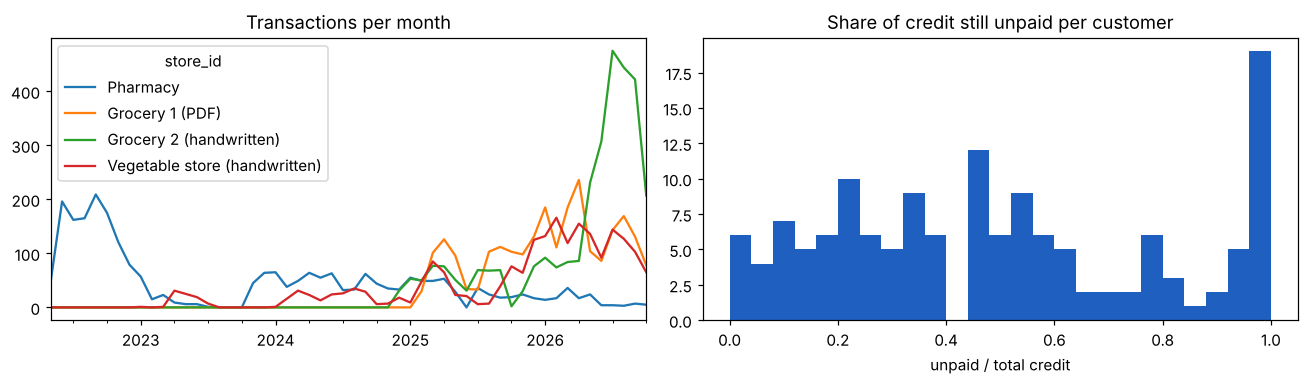

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
m = df.set_index('date').groupby('store_id').resample('ME').size().unstack(0).fillna(0)
m.rename(columns=shop_name).plot(ax=ax[0]); ax[0].set_title('Transactions per month'); ax[0].set_xlabel('')
last = df.groupby('customer_id').agg(bal=('running_balance_calc', 'last'), debt=('debt_amount', 'sum'))
ax[1].hist((last.bal / last.debt.clip(lower=1)).clip(-0.2, 1.05), bins=25, color='#1f5fbf')
ax[1].set_title('Share of credit still unpaid per customer'); ax[1].set_xlabel('unpaid / total credit')
plt.tight_layout(); plt.show()

**ملاحظة:** معظم القيود ديون؛ السداد يأتي على دفعات متفرقة (631 سداد مقابل 9,407 دين). كثير من العملاء ما زال عليهم جزء كبير من ديونهم.

## 2) تعريف الهدف دون تسرب
لا توجد تسمية جاهزة "وفي/هارب"، فبنينا الهدف من الدفتر نفسه بطريقة **اللقطات الزمنية**:

- نأخذ "لقطة" لكل عميل كل 60 يومًا (تاريخ قطع `t`).
- **الميزات** تُحسب من القيود **حتى `t` فقط** (الماضي).
- **الهدف** يُحسب من القيود **بعد `t`**: `1` إذا لم يسدد أي مبلغ خلال 180 يومًا.
- نأخذ فقط العملاء النشطين المدينين: رصيد موجب، واشترى خلال آخر 90 يومًا، و3 قيود على الأقل.

هكذا يرى النموذج الماضي فقط ويتوقع المستقبل، تمامًا كما سيحدث في الاستخدام الحقيقي.

In [4]:
L = np.log1p
FEATURES = ['recency', 'rec_rel', 'since_pay', 'n_pay', 'age_days', 'n_ev', 'bal_frac', 'pay_ratio',
            'ev_trend', 'expected_pay_overdue', 'pay_cov90', 'debt_trend']

def features_at(h, t, d0):
    """features from rows dated <= t only"""
    pay = h[h.kind == 'payment']; td = max(h.debt_amount.sum(), 1); bal = h.running_balance_calc.iloc[-1]
    r90 = h[h.date > t - pd.Timedelta(days=90)]; p90 = h[(h.date <= t - pd.Timedelta(days=90)) & (h.date > t - pd.Timedelta(days=180))]
    lastpay = pay.date.max() if len(pay) else d0
    gaps = h.date.diff().dt.days.abs().dropna(); med_gap = gaps.median() if len(gaps) else 30
    rec = (t - h.date.max()).days
    pay_gap = pay.date.diff().dt.days.abs().dropna().mean() if len(pay) > 1 else 400
    return dict(recency=L(rec), rec_rel=L(rec / max(med_gap, 1)), since_pay=L((t - lastpay).days), n_pay=len(pay),
                age_days=L((t - d0).days), n_ev=L(len(h)), bal_frac=bal / td, pay_ratio=pay.payment_amount.sum() / td,
                ev_trend=(len(r90) + 1) / (len(p90) + 1), expected_pay_overdue=L(max((t - lastpay).days - pay_gap, 0) + 1),
                pay_cov90=r90.payment_amount.sum() / max(r90.debt_amount.sum(), 1),
                debt_trend=L(r90.debt_amount.sum() + 1) - L(p90.debt_amount.sum() + 1))

rows = []
for cid, g in df.groupby('customer_id'):
    g = g.sort_values('date', kind='stable'); d0 = g.date.min(); t = d0 + pd.Timedelta(days=60)
    while t <= NOW - pd.Timedelta(days=180):
        h = g[g.date <= t]
        if len(h) >= 3 and h.running_balance_calc.iloc[-1] > 0 and (t - h.date.max()).days <= 90:
            fut = g[(g.date > t) & (g.date <= t + pd.Timedelta(days=180))]
            rows.append(dict(customer_id=cid, store=g.store_id.iloc[0], t=t, **features_at(h, t, d0),
                             balance=h.running_balance_calc.iloc[-1],
                             y=int(not (fut.kind == 'payment').any())))
        t += pd.Timedelta(days=60)
A = pd.DataFrame(rows)
X, y, groups = A[FEATURES], A.y.values, A.customer_id.values
print(f'{len(A)} snapshots from {A.customer_id.nunique()} customers | risky (no payment in 180 days): {y.mean():.0%}')

470 snapshots from 119 customers | risky (no payment in 180 days): 45%


## 3) الميزات (12 ميزة سلوكية، بلا معلومات شخصية وبلا هوية المحل)
| الميزة | المعنى |
|---|---|
| `recency` | أيام منذ آخر قيد |
| `rec_rel` | الغياب مقارنة بعادة العميل نفسه |
| `since_pay` | أيام منذ آخر سداد |
| `n_pay` | عدد مرات السداد |
| `age_days` | عمر الحساب |
| `n_ev` | عدد القيود |
| `bal_frac` | نسبة الرصيد من مجموع الدين |
| `pay_ratio` | نسبة ما سُدّد |
| `ev_trend` | نشاط آخر 3 أشهر مقابل الثلاثة قبلها |
| `expected_pay_overdue` | تأخره عن موعد سداده المعتاد |
| `pay_cov90` | ما سدّده مقابل ما اشتراه في آخر 3 أشهر |
| `debt_trend` | اتجاه حجم الدين |

**لماذا لا نستخدم نوع المحل؟** لأن النموذج قد "يحفظ" المحل بدل أن يفهم سلوك العميل؛ نستخدم المحل فقط في الاختبار.

In [5]:
corr = pd.DataFrame({'spearman_with_target': [A[f].corr(A.y, method='spearman') for f in FEATURES],
                     'AUC_alone': [max(roc_auc_score(y, A[f]), 1 - roc_auc_score(y, A[f])) for f in FEATURES]}, index=FEATURES)
display(corr.sort_values('AUC_alone', ascending=False).round(3))

,spearman_with_target,AUC_alone
recency,0.432,0.750
rec_rel,0.382,0.722
since_pay,0.230,0.633
ev_trend,-0.205,0.619
debt_trend,-0.185,0.608
n_pay,-0.163,0.594
bal_frac,0.159,0.592
pay_ratio,-0.158,0.592
n_ev,-0.122,0.571
expected_pay_overdue,0.083,0.541


**أقوى إشارة:** الغياب عن المحل (`recency`, `rec_rel`). المبالغ نفسها أضعف بكثير. صاحب المحل يعرف هذا بالخبرة: من يتوقف عن المجيء يتوقف عن السداد.

## 4) تعلم غير إشرافي: ما أنماط العملاء؟
نجمّع العملاء (كل عميل بحالته في آخر يوم من بياناته) بـ **K-Means** دون أي تسمية، ثم نرسمهم بـ **PCA** في بعدين، ونرى هل المجموعات لها معنى.

silhouette by k: {2: 0.353, 3: 0.366, 4: 0.375, 5: 0.291, 6: 0.294}


,customers,paid_share,payments,transactions,unpaid_share,days_inactive
segment,,,,,,
0,76,0.39,2.0,16,0.58,1443.5
1,44,0.57,4.0,62,0.44,66.0
2,3,0.48,2.0,174,0.52,2.0
3,18,0.82,15.0,92,0.17,207.0


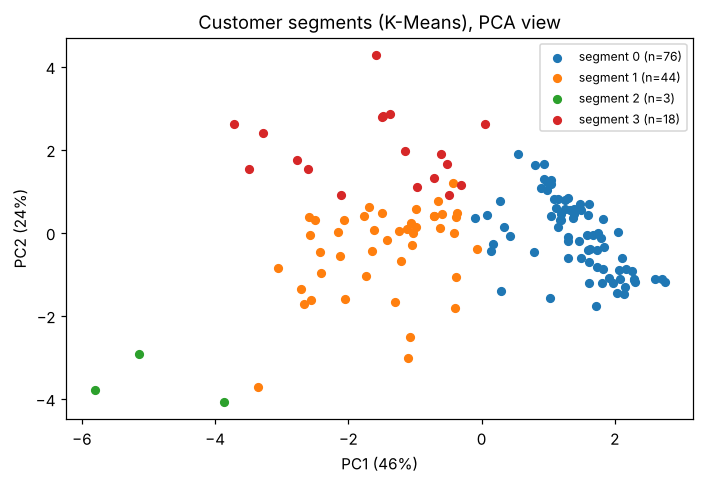

In [6]:
cust = []
for cid, g in df.groupby('customer_id'):
    g = g.sort_values('date', kind='stable')
    if len(g) >= 3:
        cust.append(dict(customer_id=cid, store=g.store_id.iloc[0], **features_at(g, NOW, g.date.min()),
                         unpaid_share=g.running_balance_calc.iloc[-1] / max(g.debt_amount.sum(), 1),
                         days_inactive=(NOW - g.date.max()).days))
Cu = pd.DataFrame(cust)
SEG = ['pay_ratio', 'n_pay', 'rec_rel', 'n_ev', 'age_days', 'ev_trend', 'expected_pay_overdue']   # behaviour over the whole history
Z = StandardScaler().fit_transform(Cu[SEG])
sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=0).fit_predict(Z)) for k in range(2, 7)}
print('silhouette by k:', {k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get) if max(sil, key=sil.get) >= 3 else 3
Cu['segment'] = KMeans(K, n_init=20, random_state=0).fit_predict(Z)
prof = Cu.groupby('segment').agg(customers=('customer_id', 'size'), paid_share=('pay_ratio', 'mean'), payments=('n_pay', 'median'),
                                 transactions=('n_ev', lambda s: int(np.expm1(s).median())), unpaid_share=('unpaid_share', 'mean'),
                                 days_inactive=('days_inactive', 'median')).round(2)
display(prof)
P2 = PCA(2).fit(Z); xy = P2.transform(Z)
plt.figure(figsize=(6.5, 4.5))
for s in sorted(Cu.segment.unique()):
    m = Cu.segment == s; plt.scatter(xy[m, 0], xy[m, 1], s=25, label=f'segment {s} (n={m.sum()})')
plt.xlabel(f'PC1 ({P2.explained_variance_ratio_[0]:.0%})'); plt.ylabel(f'PC2 ({P2.explained_variance_ratio_[1]:.0%})')
plt.title('Customer segments (K-Means), PCA view'); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**قراءة الجدول :** ظهرت 4 مجموعات بلا أي تسمية مسبقة:
- **منتظمون:** يسددون نحو 80% مما يأخذون، بسداد متكرر.
- **نشطون بديون متوسطة:** يشترون باستمرار ويسددون نحو نصف ما عليهم.
- **متوقفون بدين:** غابوا منذ زمن طويل وما زال عليهم أكثر من نصف ديونهم.
- **كبار المشترين:** عدد قليل جدًا بحركة يومية كثيفة.

هذا التقسيم يساعد صاحب المحل على فهم زبائنه حتى دون نموذج تنبؤ. (قد تختلف أرقام المجموعات قليلًا بين التشغيلات.)

## 5) تعلم إشرافي: مقارنة النماذج
**طريقة الاختبار مهمة جدًا:** لقطات العميل الواحد متشابهة، فإذا ظهر العميل في التدريب والاختبار معًا تكون الدقة مضخّمة. لذلك نستخدم `StratifiedGroupKFold`: **العميل المختبَر لم يره النموذج أبدًا.**

نقارن أيضًا بـ **قاعدة بسيطة بلا تعلم آلة:** "أيام منذ آخر شراء".

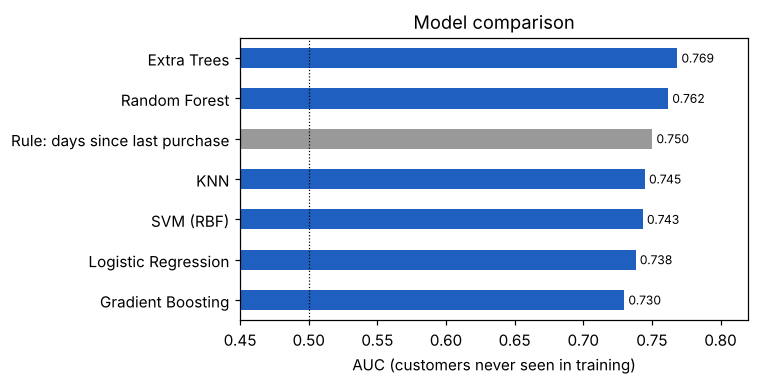

In [7]:
def P(m): return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('m', m)])
MODELS = {
    'Logistic Regression': lambda: P(LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000)),
    'KNN': lambda: P(KNeighborsClassifier(30, weights='distance')),
    'SVM (RBF)': lambda: P(SVC(probability=True, class_weight='balanced', random_state=0)),
    'Random Forest': lambda: P(RandomForestClassifier(300, min_samples_leaf=10, max_features=0.5, class_weight='balanced_subsample', random_state=0, n_jobs=-1)),
    'Gradient Boosting': lambda: P(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=20, class_weight='balanced', random_state=0)),
    'Extra Trees': lambda: P(ExtraTreesClassifier(300, min_samples_leaf=10, max_features=0.5, class_weight='balanced_subsample', random_state=0, n_jobs=-1)),
}
def grouped_cv(make, reps=3):
    preds, aucs = [], []
    for r in range(reps):
        p = np.zeros(len(A))
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(X, y, groups):
            assert not set(groups[tr]) & set(groups[te])          # no customer in both
            p[te] = make().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
        preds.append(p); aucs.append(roc_auc_score(y, p))
    return np.mean(preds, 0), np.mean(aucs)
results, PRED = {}, {}
for name, mk in MODELS.items():
    PRED[name], results[name] = grouped_cv(mk)
results['Rule: days since last purchase'] = roc_auc_score(y, A.recency)
res = pd.Series(results).sort_values()
ax = res.plot.barh(figsize=(7, 3.6), color=['#999' if 'Rule' in i else '#1f5fbf' for i in res.index])
for i, v in enumerate(res): ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8)
ax.axvline(0.5, color='k', lw=0.8, ls=':'); ax.set_xlim(0.45, 0.82); ax.set_xlabel('AUC (customers never seen in training)')
ax.set_title('Model comparison'); plt.tight_layout(); plt.show()

**النتيجة:** Extra Trees الأفضل، لكن الفارق عن القاعدة البسيطة صغير. نماذج التعزيز (Boosting) أضعف لأنها تحفظ العينات الصغيرة.

## 6) التقييم الصارم للنموذج المختار (Extra Trees)
نقيس بعدة طرق، لأن رقمًا واحدًا لا يكفي:

In [8]:
p = PRED['Extra Trees']
# 95% confidence interval by resampling customers
rng = np.random.default_rng(0); cs = A.customer_id.unique(); boot = []
for _ in range(1000):
    idx = np.concatenate([np.where(groups == c)[0] for c in rng.choice(cs, len(cs))]); boot.append(roc_auc_score(y[idx], p[idx]))
print(f'AUC = {results["Extra Trees"]:.3f}  (95% CI {np.percentile(boot, 2.5):.2f}–{np.percentile(boot, 97.5):.2f})')
print(f'Brier = {brier_score_loss(y, p):.3f}  (guessing the average: {y.mean() * (1 - y.mean()):.3f})')
print('\nThreshold   accuracy  recall(risky)  precision')
for th in (0.4, 0.5, 0.6):
    pr = p >= th; print(f'   {th}        {accuracy_score(y, pr):.2f}       {recall_score(y, pr):.2f}          {precision_score(y, pr):.2f}')
print(f'(always predicting the majority class gives accuracy {max(y.mean(), 1 - y.mean()):.2f})')

print('\nLeave one shop out (train on the other shops, test on a shop the model never saw):')
for st in sorted(A.store.unique()):
    te = (A.store == st).values
    if te.sum() < 30 or len(set(y[te])) < 2 or len(set(y[~te])) < 2: continue
    q = MODELS['Extra Trees']().fit(X[~te], y[~te]).predict_proba(X[te])[:, 1]
    print(f'   {shop_name(st):28s} AUC = {roc_auc_score(y[te], q):.3f}  (n={te.sum()})')
cut = A.t.quantile(0.7); tr = (A.t < cut).values
q = MODELS['Extra Trees']().fit(X[tr], y[tr]).predict_proba(X[~tr])[:, 1]
print(f'\nTime split (train before {cut.date()}, test after): model AUC = {roc_auc_score(y[~tr], q):.3f} | rule AUC = {roc_auc_score(y[~tr], A.recency[~tr]):.3f}')
sh = []
for k in range(5):
    ys = rng.permutation(y); ps = np.zeros(len(A))
    for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=k).split(X, ys, groups): ps[b] = MODELS['Extra Trees']().fit(X.iloc[a], ys[a]).predict_proba(X.iloc[b])[:, 1]
    sh.append(roc_auc_score(ys, ps))
print(f'Leakage check — shuffled labels give AUC = {np.mean(sh):.3f} on average of 5 shuffles (must be ≈ 0.5)')

AUC = 0.769  (95% CI 0.72–0.82)
Brier = 0.196  (guessing the average: 0.247)

Threshold   accuracy  recall(risky)  precision
   0.4        0.67       0.83          0.59
   0.5        0.69       0.69          0.64
   0.6        0.69       0.53          0.70
(always predicting the majority class gives accuracy 0.55)

Leave one shop out (train on the other shops, test on a shop the model never saw):
   Pharmacy                     AUC = 0.744  (n=329)
   Grocery 1 (PDF)              AUC = 0.773  (n=69)
   Vegetable store (handwritten) AUC = 0.632  (n=63)

Time split (train before 2025-06-18, test after): model AUC = 0.709 | rule AUC = 0.665
Leakage check — shuffled labels give AUC = 0.510 on average of 5 shuffles (must be ≈ 0.5)


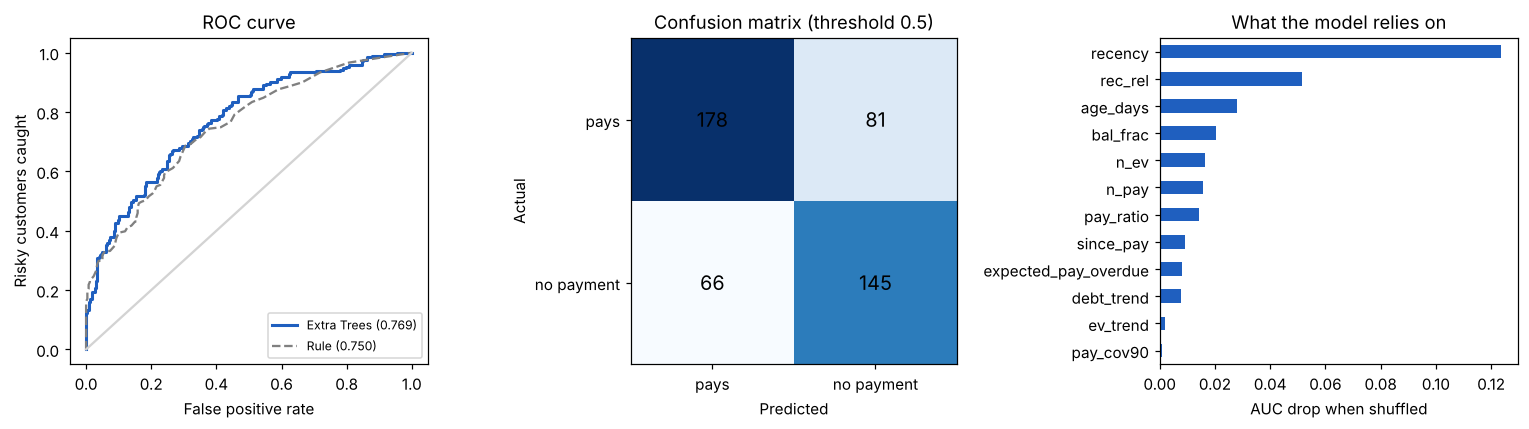

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
f1, t1, _ = roc_curve(y, p); f2, t2, _ = roc_curve(y, A.recency)
ax[0].plot(f1, t1, lw=2, color='#1f5fbf', label=f'Extra Trees ({results["Extra Trees"]:.3f})')
ax[0].plot(f2, t2, lw=1.5, ls='--', color='grey', label=f'Rule ({results["Rule: days since last purchase"]:.3f})')
ax[0].plot([0, 1], [0, 1], color='lightgrey'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('Risky customers caught')
ax[0].set_title('ROC curve'); ax[0].legend(fontsize=8, loc='lower right')
cm = confusion_matrix(y, p >= 0.5); ax[1].imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, v, ha='center', va='center', fontsize=13)
ax[1].set_xticks([0, 1], ['pays', 'no payment']); ax[1].set_yticks([0, 1], ['pays', 'no payment'])
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Actual'); ax[1].set_title('Confusion matrix (threshold 0.5)')
final = MODELS['Extra Trees']().fit(X, y)
imp = permutation_importance(final, X, y, scoring='roc_auc', n_repeats=10, random_state=0)
pd.Series(imp.importances_mean, FEATURES).sort_values().plot.barh(ax=ax[2], color='#1f5fbf')
ax[2].set_title('What the model relies on'); ax[2].set_xlabel('AUC drop when shuffled')
plt.tight_layout(); plt.show()

**كيف نقرأ هذه الأرقام بصدق :**
- AUC ≈ 0.77 على عملاء لم يرهم النموذج، و≈ 0.71 على المستقبل (أفضل من القاعدة ≈ 0.67).
- يصمد مع محل جديد من نوع مشابه (≈ 0.74–0.77)، ويضعف مع متجر الخضروات (≈ 0.63)، فكل محل جديد يُراقب أولًا.
- خلط التسميات يعطي ≈ 0.5، فلا يوجد تسرب.
- اختبرنا أيضًا على **28 عميلًا عُزلوا من البداية**: AUC ≈ 0.70، فالتقدير الصادق **بين 0.70 و0.77**.

## 7) ما جرّبناه لرفع الدقة ولم ينجح (وهذه نتيجة علمية بحد ذاتها)
الجدول التالي نتائج مسجّلة من تجارب منفصلة (موثقة في `docs/experiments.md`). كل البيانات الإضافية دخلت **التدريب فقط**، والاختبار دائمًا على عملائنا الحقيقيين.

In [10]:
tried = pd.DataFrame([
    ('Reference: our data only (Extra Trees, 12 features)',            0.769, 'reference'),
    ('+ SMOTE / synthetic rows from our own data',                      0.766, 'no gain'),
    ('+ Generated "customers" (200 synthetic ledgers)',                 0.675, 'worse'),
    ('+ Give Me Some Credit (Kaggle, 150k bank customers)',             0.558, 'worse'),
    ('+ B2B invoices (Kaggle, 50k invoices)',                           0.753, 'worse'),
    ('+ OneFi (Nigerian lender, 4,359 customers)',                      0.770, 'no gain'),
    ('+ Kenya Financial Diaries (household shop credit)',               0.756, 'worse'),
    ('12 models, tuning (nested CV), voting & stacking',                0.768, 'no gain'),
    ('+ 12 extra behavioural features / entry details / customer age',  0.764, 'no gain'),
], columns=['experiment', 'AUC on our real customers', 'verdict'])
display(tried)

,experiment,AUC on our real customers,verdict
0,"Reference: our data only (Extra Trees, 12 features)",0.769,reference
1,+ SMOTE / synthetic rows from our own data,0.766,no gain
2,"+ Generated ""customers"" (200 synthetic ledgers)",0.675,worse
3,"+ Give Me Some Credit (Kaggle, 150k bank customers)",0.558,worse
4,"+ B2B invoices (Kaggle, 50k invoices)",0.753,worse
5,"+ OneFi (Nigerian lender, 4,359 customers)",0.770,no gain
6,+ Kenya Financial Diaries (household shop credit),0.756,worse
7,"12 models, tuning (nested CV), voting & stacking",0.768,no gain
8,+ 12 extra behavioural features / entry details / customer age,0.764,no gain


**لماذا؟** البيانات الخارجية لسلوك مختلف (بنوك، شركات، قروض بموعد ثابت). والبيانات الاصطناعية لا تحمل معلومة جديدة. ومنحنى التعلم يقول: كل مضاعفة لعدد **العملاء الحقيقيين** تضيف ≈ 0.02 AUC. أي أن **ما يرفع الدقة هو معلومات جديدة عن عملائنا أنفسهم، لا خوارزمية أعقد.**

**تحقق من الواقع:** قارنّا تصنيف أصحاب المحلات (ملتزم/متأخر/هارب) لـ 34 عميلًا بتوقع النموذج الذي لم يرَ هذا التصنيف: اتفاق AUC ≈ 0.67–0.75.

## 8) القيمة العملية: من نتابع أولًا؟
نرتّب العملاء حسب **الخسارة المتوقعة = احتمال عدم السداد × الرصيد**. السؤال: لو تابع صاحب المحل أعلى 20% فقط من القائمة، كم يغطي من الديون التي لم تُسدَّد فعلًا؟

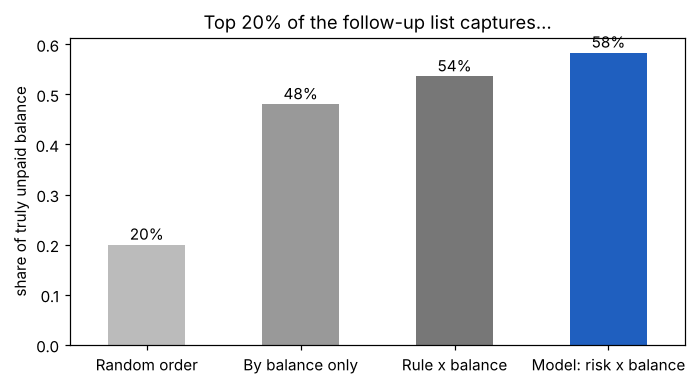

In [11]:
lost = A.balance.values * y; top = int(0.2 * len(A))
def captured(score): return lost[np.argsort(-score)[:top]].sum() / lost.sum()
cap = pd.Series({'Random order': 0.20, 'By balance only': captured(A.balance.values),
                 'Rule x balance': captured(A.recency.values * A.balance.values), 'Model: risk x balance': captured(p * A.balance.values)})
ax = cap.plot.bar(figsize=(6.5, 3.6), color=['#bbb', '#999', '#777', '#1f5fbf'], rot=0)
for i, v in enumerate(cap): ax.text(i, v + 0.01, f'{v:.0%}', ha='center')
ax.set_ylabel('share of truly unpaid balance'); ax.set_title('Top 20% of the follow-up list captures...'); plt.tight_layout(); plt.show()

In [12]:
# today's follow-up list (customer IDs only — names stay with the shop owner)
today = []
for cid, g in df.groupby('customer_id'):
    g = g.sort_values('date', kind='stable')
    if len(g) >= 3 and g.running_balance_calc.iloc[-1] > 0 and (NOW - g.date.max()).days <= 90:
        today.append(dict(customer_id=cid, shop=shop_name(g.store_id.iloc[0]), **features_at(g, NOW, g.date.min()),
                          balance=g.running_balance_calc.iloc[-1], days_since_purchase=(NOW - g.date.max()).days))
T = pd.DataFrame(today); T['risk'] = final.predict_proba(T[FEATURES])[:, 1]
T['expected_loss'] = T.risk * T.balance
T['level'] = np.select([T.risk >= 0.79, T.risk >= 0.5], ['HIGH', 'MEDIUM'], 'low')
display(T.sort_values('expected_loss', ascending=False)[['customer_id', 'shop', 'level', 'risk', 'balance', 'expected_loss', 'days_since_purchase']].head(10).round(2))

,customer_id,shop,level,risk,balance,expected_loss,days_since_purchase
1,C087,Grocery 1 (PDF),MEDIUM,0.57,203100.0,115450.97,12
8,C114,Grocery 2 (handwritten),MEDIUM,0.68,165440.0,111939.98,54
9,C115,Grocery 2 (handwritten),MEDIUM,0.57,171040.0,98059.35,19
12,C118,Grocery 2 (handwritten),low,0.27,175780.0,46808.23,2
13,C120,Grocery 2 (handwritten),MEDIUM,0.55,75090.0,41316.85,43
18,C127,Vegetable store (handwritten),MEDIUM,0.72,47410.0,34230.24,60
11,C117,Grocery 2 (handwritten),low,0.31,102560.0,31604.65,2
10,C116,Grocery 2 (handwritten),MEDIUM,0.61,40230.0,24622.13,40
19,C128,Vegetable store (handwritten),MEDIUM,0.79,30600.0,24036.23,63
14,C123,Vegetable store (handwritten),low,0.46,26380.0,12072.18,7


## 9) الخلاصة
1. **بيانات حقيقية جمعناها بأنفسنا** من 4 محلات، بعضها من دفاتر بخط اليد.
2. **تعلم غير إشرافي** كشف أنماطًا واضحة للعملاء؛ **وتعلم إشرافي** يتوقع عدم السداد بـ AUC بين 0.70 و0.77 على عملاء جدد، مع حماية من التسرب وانحياز الاختيار.
3. **الإشارة الأقوى:** الغياب عن المحل، لا حجم الدين.
4. **القيمة العملية:** أعلى 20% من قائمة المتابعة تغطي ≈ 58% من الديون الضائعة.
5. **حدود صريحة:** 119 عميلًا فقط؛ لا يتنبأ بالعميل الجديد تمامًا؛ يضعف مع نوع محل مختلف؛ **لا يرفض أحدًا آليًا** — ينبّه ويشرح، وصاحب المحل يقرر.
6. **الخطوة القادمة:** محلات أكثر، وتسجيل الضامن وموعد الدخل والطلبات المرفوضة، ومراقبة شهرية وإعادة تدريب.